# Ejercicio 05 · Recomendación Top-10 con MovieLens
Alexis De La Cruz · 100805370 · INF-8239 · Unidad 03

Base oficial LAB08–LAB09 de Edwin Ramón José Nolasco. Adaptaciones: docs/CORRECCIONES_BASE.md; apoyo y controles: AI_USE_DECLARATION.md.

## Protocolo previo
Siete configuraciones: conteo, popularidad suavizada, contenido por géneros, MF10/MF20 e híbridos α0.25/0.75 (peso colaborativo). MF:12 épocas, semillas42/7/2026. Corte global80/10/10 sin dividir timestamps iguales. Catálogo observado al corte, excluyendo vistos. Relevante ≥4; k10. Selección en validación: a ≤0.005 del máximo NDCG, mayor cobertura y menor ajuste. Decisión registrada antes de prueba, sin volver a seleccionar con sus resultados.

In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'src'))
import pandas as pd
from IPython.display import display,Image,Markdown
print('Python:',sys.executable)
assert sys.version_info[:2]==(3,12)

Python: C:\Users\Alexis De La Cruz\.venvs\u03-rec\.venv\Scripts\python.exe


## Descarga, auditoría y ejecución completa
Huella en docs/data_source.json; descarga falla si cambia. No se redistribuyen datos ni historiales. El experimento siguiente sí recalcula las métricas.

In [2]:
from scripts.run_exercise05 import main
main()

validation seed 42 factors 10 fit 6.21


validation seed 42 factors 20 fit 6.24


validation seed 7 factors 10 fit 6.39


validation seed 7 factors 20 fit 6.49


validation seed 2026 factors 10 fit 6.54


...

test seed 7 factors 20 fit 7.56


test seed 2026 factors 10 fit 7.89


test seed 2026 factors 20 fit 7.37


              ndcg  ndcg_std     hit  precision  recall  coverage  diversity  novelty    rmse   fit_s  predict_ms_per_user   size_kib  users  users_positive  users_no_positive  cold_users  unreachable_positives  pareto  selected
model                                                                                                                                                                                                                               
content     0.2123    0.0000  0.5694     0.1778  0.0462    0.0151     0.5830  10.6776  1.0686  0.0645               1.4124   280.5225     74              72                  2          47                    652   False     False
count       0.2576    0.0000  0.6250     0.2264  0.0613    0.0085     0.7867   8.6826  1.0686  0.0645               0.9029    38.4629     74              72                  2          47                    652    True      True
hybrid25    0.2262    0.0012  0.6250     0.1903  0.0488    0.0201     0.6022  10.398

DURACIÓN: 97.3 s


## Datos y separación temporal
La separación global impide usar calificaciones posteriores de otros usuarios, riesgo del leave-last individual del ejemplo. Puede producir muchos usuarios nuevos; se conservan y reciben fallback. El metadato de géneros es estático y no tiene fecha histórica verificable.

In [3]:
meta=json.loads((ROOT/'reports/metrics.json').read_text(encoding='utf-8'))
display(pd.Series(meta['dataset']).to_frame('valor'))
display(pd.Series(meta['split']).to_frame('valor'))

,valor
ratings,100836
users,610
movies,9742
rated_movies,9724
density,0.016968
duplicates,0
date_min,1996-03-29 18:36:55+00:00
date_max,2018-09-24 14:27:30+00:00
sha256,696d65a3dfceac7c45750ad32df2c259311949efec81f0...


,valor
train,80669
validation,10083
test,10084
cuts,"{'train_end': 1458635171, 'validation_end': 14..."
assignment_sha256,688196fecf11dcbdbfaa22df2dfcd2f2550b98f1e31c92...


## Validación y decisión previa a prueba

In [4]:
validation=pd.read_csv(ROOT/'reports/validation_runs.csv')
display(validation.groupby('model')[['ndcg','coverage','fit_s']].mean())
display(json.loads((ROOT/'reports/decision_locked.json').read_text(encoding='utf-8')))

,ndcg,coverage,fit_s
model,,,
content,0.224291,0.017415,0.099833
count,0.288662,0.007118,0.099833
hybrid25,0.231759,0.020169,6.482433
hybrid75,0.236822,0.015932,6.482433
mf10,0.239762,0.013474,6.481392
mf20,0.241203,0.014745,6.482433
popularity,0.232184,0.005466,0.099833


{'chosen': 'count',
 'rule': 'NDCG a .005 del máximo; mayor cobertura, menor costo',
 'source': 'validation_runs.csv',
 'locked_before_test': True,
 'locked_utc': '2026-10-19T17:33:29.342189+00:00'}

## Prueba final
Precision divide entre10; recall entre relevantes futuros; NDCG valora posición; HitRate es al menos un acierto. Se promedian usuarios con positivos. Los demás se cuentan aparte; positivos fuera de catálogo cuentan como fallos. Cobertura/diversidad/novedad usan todas las listas. La desviación de3 semillas no es intervalo de confianza. Baselines deterministas se repiten como controles.

RMSE en MF evalúa calificaciones con fallback para pares nuevos; en híbridos corresponde al componente MF; en contenido/popularidad a una media de referencia, no al score Top-N.

,ndcg,ndcg_std,hit,precision,recall,coverage,diversity,novelty,rmse,fit_s,predict_ms_per_user,size_kib,users,users_positive,users_no_positive,cold_users,unreachable_positives,pareto,selected
model,,,,,,,,,,,,,,,,,,,
content,0.21229,0.00000,0.56944,0.17778,0.04625,0.01514,0.58299,10.67763,1.06857,0.06453,1.41244,280.52246,74,72,2,47,652,False,False
count,0.25760,0.00000,0.62500,0.22639,0.06130,0.00850,0.78668,8.68258,1.06857,0.06453,0.90294,38.46289,74,72,2,47,652,True,True
hybrid25,0.22622,0.00116,0.62500,0.19028,0.04878,0.02011,0.60219,10.39866,1.06011,7.62354,2.02765,1710.53906,74,72,2,47,652,False,False
hybrid75,0.24665,0.00269,0.70370,0.20694,0.05644,0.01642,0.75173,9.58107,1.06011,7.62354,1.92469,1710.53906,74,72,2,47,652,False,False
mf10,0.23275,0.00430,0.66204,0.19491,0.05416,0.01308,0.80526,9.41267,1.06049,8.47415,1.80957,779.33887,74,72,2,47,652,False,False
mf20,0.23518,0.00185,0.68056,0.19861,0.05536,0.01491,0.80814,9.46652,1.06011,7.62354,1.89978,1466.46191,74,72,2,47,652,False,False
popularity,0.24337,0.00000,0.65278,0.20417,0.05604,0.00524,0.80161,9.28058,1.06857,0.06453,1.05662,38.45703,74,72,2,47,652,False,False


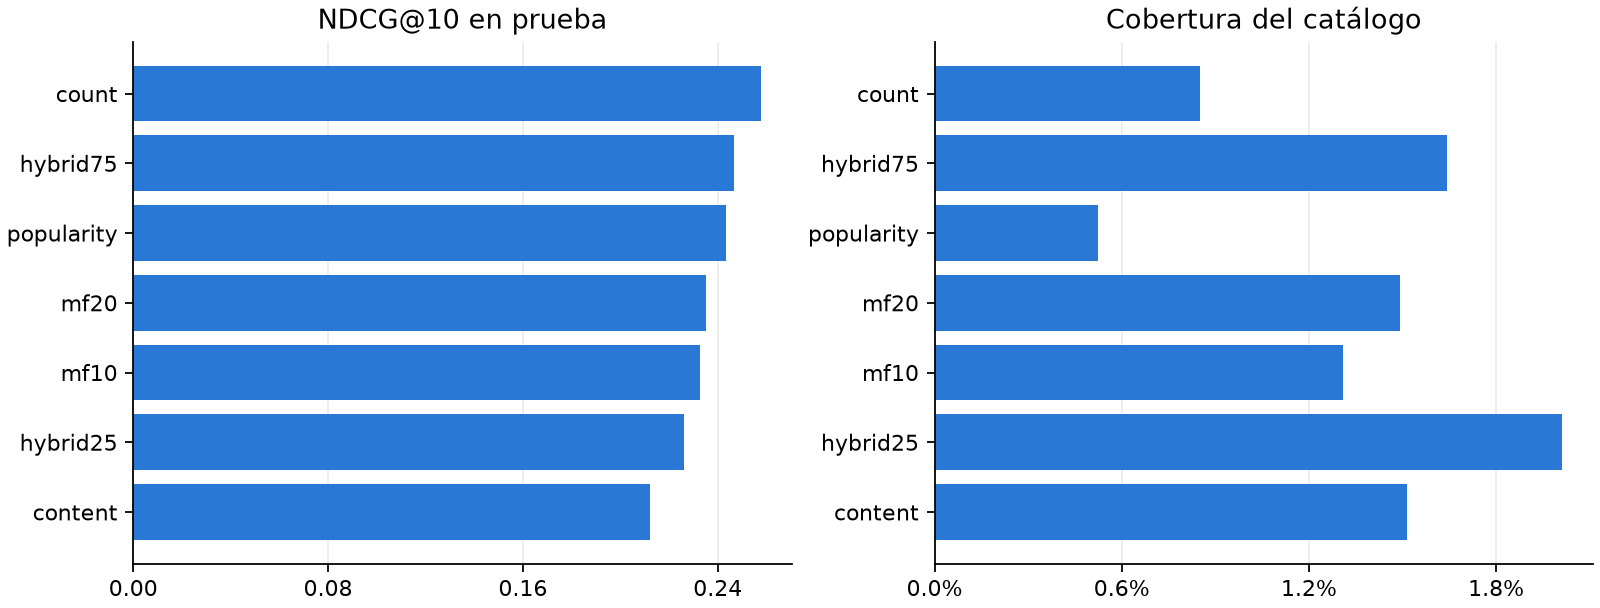

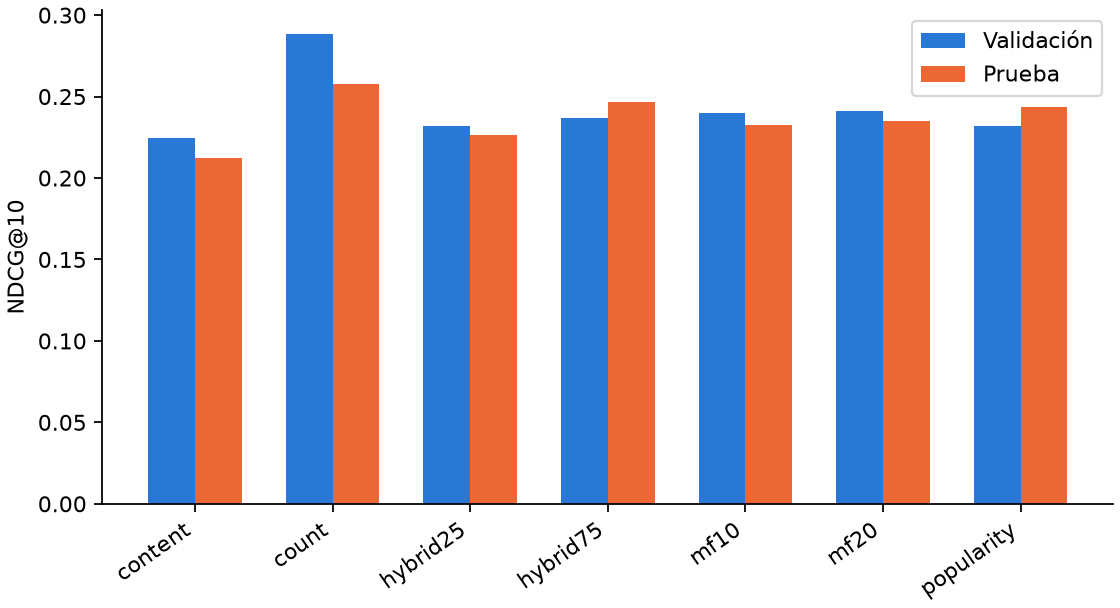

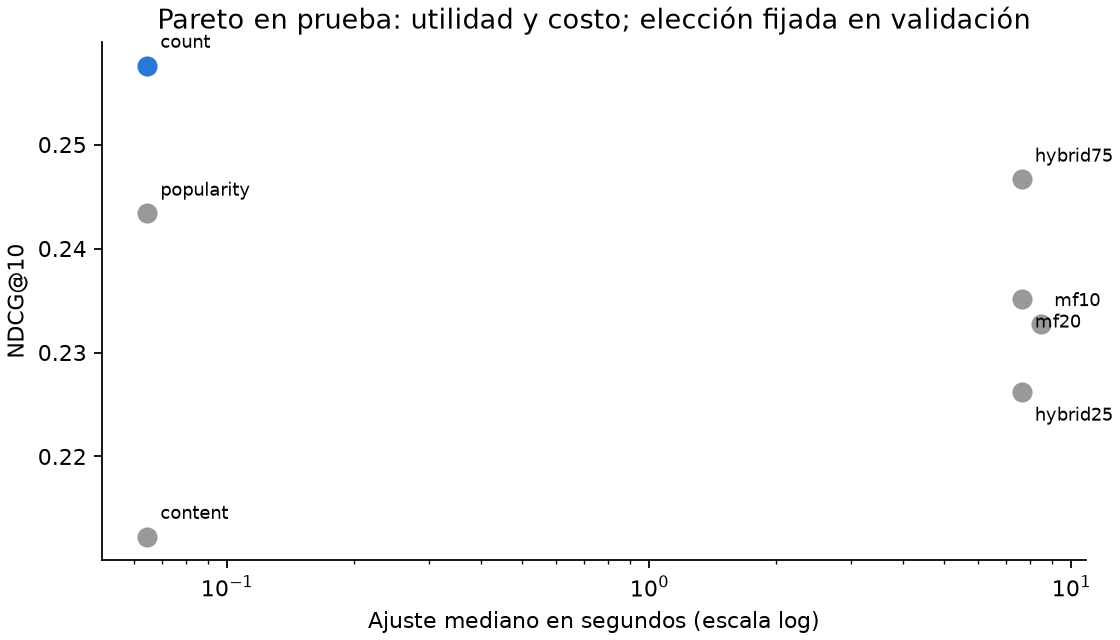

In [5]:
results=pd.read_csv(ROOT/'reports/main_results.csv',index_col='model')
display(results.round(5))
display(Image(filename=str(ROOT/'reports/figures/ranking_coverage.png')))
display(Image(filename=str(ROOT/'reports/figures/validation_test.png')))
display(Image(filename=str(ROOT/'reports/figures/pareto.png')))

## Perfiles y contenido
Historial amplio y pequeño son extremos observados; nuevo es sintético. Similitud de géneros puede producir listas repetidas y no mide satisfacción. No hay variables para comprobar equidad demográfica. La frontera de prueba es descriptiva: no modifica la elección.

In [6]:
display(pd.read_csv(ROOT/'reports/profiles.csv'))
display(pd.read_csv(ROOT/'reports/segments.csv'))
display(pd.read_csv(ROOT/'reports/content_queries.csv'))

,profile,user,rank,movieId,title,genres,history,fallback
0,amplio,414,1,1258,"Shining, The (1980)",Horror,2581,False
1,amplio,414,2,19,Ace Ventura: When Nature Calls (1995),Comedy,2581,False
2,amplio,414,3,410,Addams Family Values (1993),Children|Comedy|Fantasy,2581,False
3,amplio,414,4,1219,Psycho (1960),Crime|Horror,2581,False
4,amplio,414,5,2324,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War,2581,False
5,amplio,414,6,8368,Harry Potter and the Prisoner of Azkaban (2004),Adventure|Fantasy|IMAX,2581,False
6,amplio,414,7,317,"Santa Clause, The (1994)",Comedy|Drama|Fantasy,2581,False
7,amplio,414,8,520,Robin Hood: Men in Tights (1993),Comedy,2581,False
8,amplio,414,9,2710,"Blair Witch Project, The (1999)",Drama|Horror|Thriller,2581,False
9,amplio,414,10,435,Coneheads (1993),Comedy|Sci-Fi,2581,False


,model,segment,ndcg,hit,precision,recall
0,content,con_historial,0.014283,0.120000,0.012000,0.002945
1,content,frio,0.317609,0.808511,0.265957,0.069284
2,count,con_historial,0.088902,0.280000,0.080000,0.032940
3,count,frio,0.347334,0.808511,0.304255,0.076390
4,hybrid25,con_historial,0.054415,0.280000,0.048000,0.010230
5,hybrid25,frio,0.317609,0.808511,0.265957,0.069284
6,hybrid75,con_historial,0.113246,0.506667,0.096000,0.032307
7,hybrid75,frio,0.317609,0.808511,0.265957,0.069284
8,mf10,con_historial,0.073230,0.386667,0.061333,0.025724
9,mf10,frio,0.317609,0.808511,0.265957,0.069284


,movieId,title,genres,content_score,query
0,166461,Moana (2016),Adventure|Animation|Children|Comedy|Fantasy,1.0,Toy Story (1995)
1,53121,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,1.0,Toy Story (1995)
2,103755,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,1.0,Toy Story (1995)
3,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0,Toy Story (1995)
4,4016,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0,Toy Story (1995)
5,3754,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0,Toy Story (1995)
6,136016,The Good Dinosaur (2015),Adventure|Animation|Children|Comedy|Fantasy,1.0,Toy Story (1995)
7,45074,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,1.0,Toy Story (1995)
8,65577,"Tale of Despereaux, The (2008)",Adventure|Animation|Children|Comedy|Fantasy,1.0,Toy Story (1995)
9,2294,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1.0,Toy Story (1995)


## Interpretación y documentos generados con resultados reales

In [7]:
import subprocess
subprocess.run([sys.executable,str(ROOT/'scripts/report_exercise05.py')],check=True)
display(Markdown((ROOT/'reports/conclusion.md').read_text(encoding='utf-8')))

# Conclusión personal — borrador para revisión del autor

En esta práctica quise comprobar si un recomendador más complejo realmente ayudaba a ordenar mejor las películas. Partí de MovieLens y comparé siete configuraciones, desde un conteo de popularidad hasta factorización e híbridos. Lo primero que tuve que aclarar fue qué significaba acertar: consideré relevante una película con cuatro estrellas o más y evalué listas de diez títulos. Predecir una calificación cercana a la real y recomendar una película que aparezca entre los intereses futuros son tareas relacionadas, pero no equivalentes.

Para evitar usar información del futuro, separé las interacciones por fecha en entrenamiento, validación y prueba. Esta decisión hizo más exigente la evaluación: de los 74 usuarios de prueba, 47 todavía no tenían historial al momento del ajuste final. A esos usuarios les ofrecí conteo de popularidad. Por eso no puedo interpretar sus listas como recomendaciones personalizadas. También conservé los positivos que estaban fuera del catálogo como fallos, porque eliminarlos habría dado una impresión demasiado favorable del sistema.

Con la regla fijada antes de revisar prueba, seleccioné Conteo. En validación alcanzó NDCG@10 de 0.2887; en prueba obtuvo 0.2576 y cobertura de 0.9%. La popularidad suavizada obtuvo 0.2434. El mayor NDCG observado en prueba correspondió a Conteo, con 0.2576, pero ese resultado posterior no se utilizó para cambiar la elección. Para mí, separar ambas decisiones es una parte importante del ejercicio: de lo contrario estaría ajustando el sistema a la misma prueba con la que pretendo justificarlo.

Entre los usuarios con historial, el híbrido α0.75 obtuvo NDCG 0.1132 frente a 0.0889 del conteo. Ese contraste me hizo bajar las expectativas de encontrar un ganador universal. La revisión de los perfiles me ayudó a entender los límites de cada enfoque. Con pocos datos del usuario, el respaldo de popularidad es fácil de explicar, aunque repite títulos. El contenido aprovecha géneros y puede ampliar el catálogo recomendado, pero conocer los géneros no significa conocer toda la película. La factorización incorpora patrones compartidos y añade tiempo de ajuste; mezclarla con contenido tampoco garantiza una mejora. La cobertura y la diversidad sirven para describir esas diferencias, sin reemplazar la relevancia.

Me quedo con un procedimiento que puedo volver a ejecutar y revisar: descarga con huella, cortes guardados, candidatos comunes, tres semillas y pruebas de los casos delicados. Los resultados corresponden a este conjunto histórico y a este protocolo; no demuestran cómo responderían personas reales en una aplicación. Antes de llevarlo a producción comprobaría el arranque en frío, contrastaría otras ventanas temporales y mediría utilidad con usuarios, manteniendo separada una evaluación final.


## Integridad de la ejecución

In [8]:
from inf8239_u03.data import load_movielens
from inf8239_u03.config import MOVIELENS_DIR
from inf8239_u03.protocol import global_time_split
r,m=load_movielens(MOVIELENS_DIR)
tr,va,te,_=global_time_split(r)
assert tr.timestamp.max()<va.timestamp.min()<=va.timestamp.max()<te.timestamp.min()
assert len(tr)+len(va)+len(te)==len(r)
assert len(validation)==21 and len(results)==7
assert results.ndcg.between(0,1).all()
print('Integridad comprobada. Pruebas adicionales: python -m pytest -q')

Integridad comprobada. Pruebas adicionales: python -m pytest -q
